In [1]:
a = 100      # price when nothing is sold
b = 1        # demand falls by b for each unit of price
cost = 20    # cost to produce one unit

In [2]:
demand = function(p) pmax(a - b * p, 0)

In [3]:
profit_one = function(p_own, p_rival) {
  ifelse(p_own < p_rival, (p_own - cost) * demand(p_own),
  ifelse(p_own == p_rival, (p_own - cost) * demand(p_own) / 2, 0))
}

In [4]:
cat("Rival charges 50.\n")
cat("  Match at 50:     profit =", profit_one(50, 50), "\n")
cat("  Undercut to 49:  profit =", profit_one(49, 50), "\n\n")

Rival charges 50.
  Match at 50:     profit = 750 
  Undercut to 49:  profit = 1479 



In [5]:
# Comparison between three market outcomes
outcomes = data.frame(
  market = c("Monopoly", "Cournot duopoly (quantity)", "Bertrand duopoly (price)"),
  price  = c((a + cost) / 2, (a + 2 * cost) / 3, cost),
  profit_per_firm = c(((a - cost)^2) / (4 * b),         
                      ((a - cost)^2) / (9 * b),         
                      0)
)
print(outcomes, digits = 4)

par(mfrow = c(1, 2))

                      market price profit_per_firm
1                   Monopoly 60.00          1600.0
2 Cournot duopoly (quantity) 46.67           711.1
3   Bertrand duopoly (price) 20.00             0.0


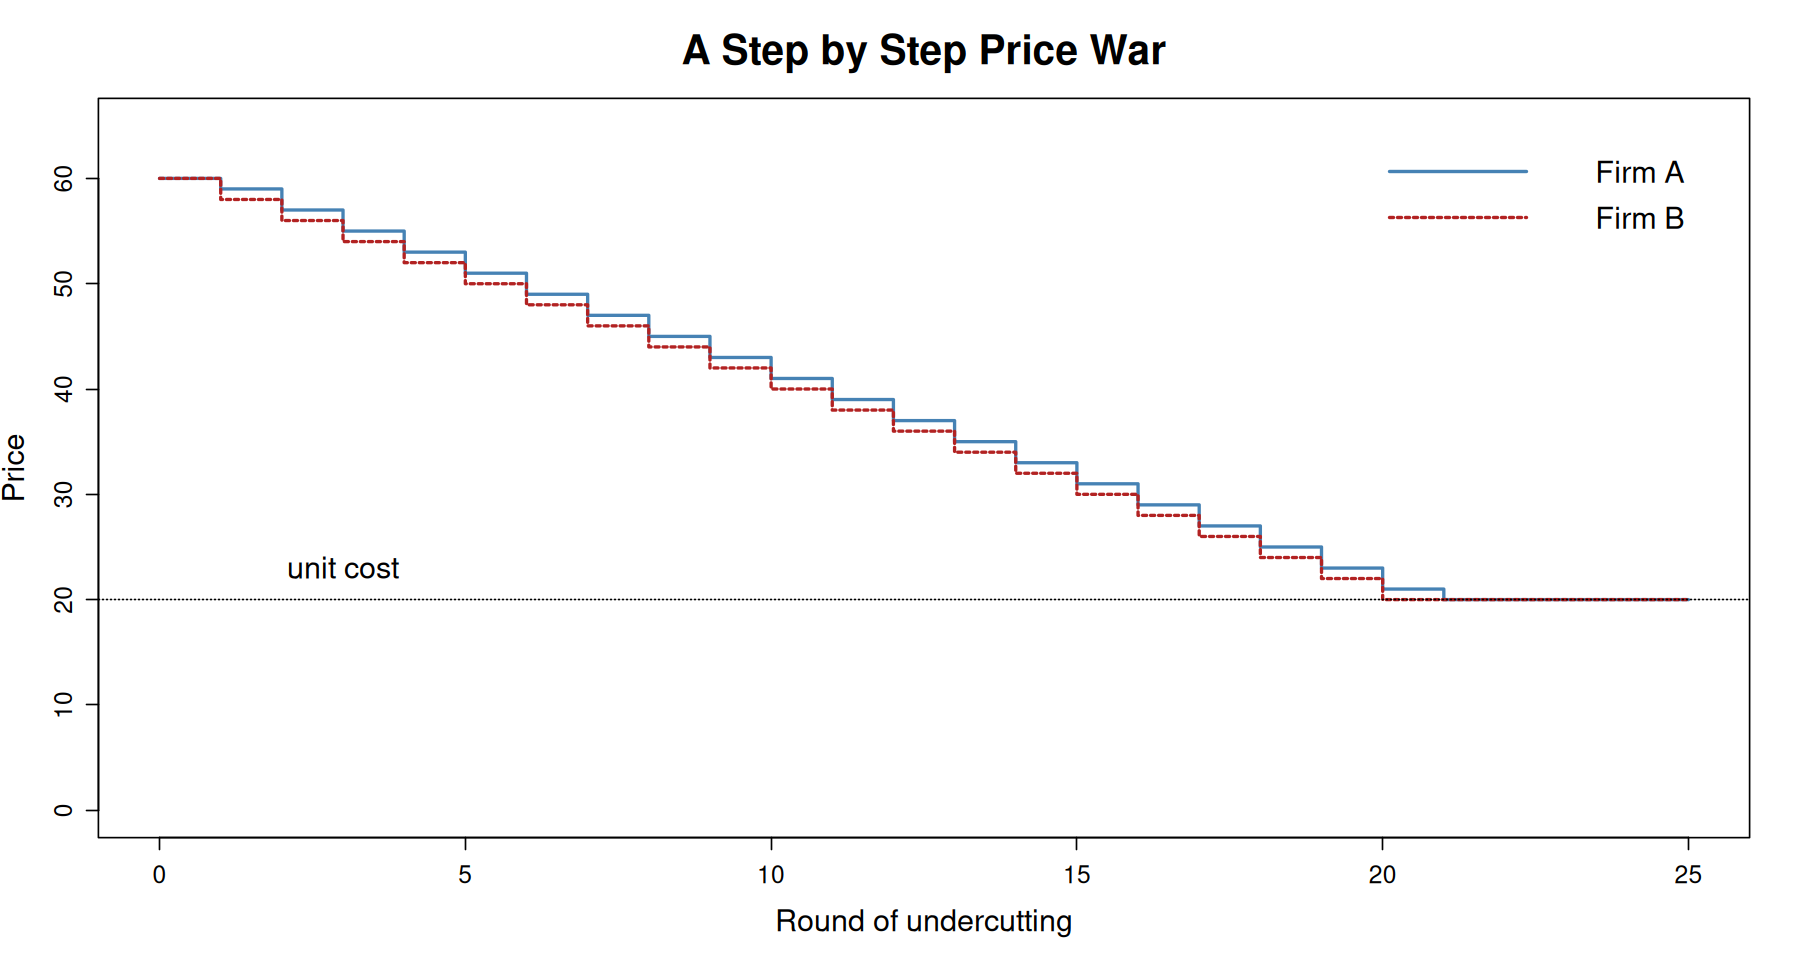

In [7]:
# A step by step price war
options(repr.plot.width=15, repr.plot.height=8)
start = (a + cost) / 2
pa = pb = start
path_a = pa
path_b = pb
for (round in 1:25) {
  pa = max(pb - 1, cost)
  pb = max(pa - 1, cost)
  path_a = c(path_a, pa)
  path_b = c(path_b, pb)
}
plot(0:25, path_a, type = "s", lwd = 2, col = "steelblue",
     ylim = c(0, 65), xlab = "Round of undercutting", 
     ylab = "Price", cex.lab = 1.5, cex.axis = 1.2,
     main = "A Step by Step Price War", cex.main = 2)
lines(0:25, path_b, type = "s", lwd = 2, col = "firebrick", lty = 2)
abline(h = cost, lty = 3)
text(3, cost + 3, "unit cost", cex = 1.5)
legend(19, 65, bty = "n", lwd = 2, lty = c(1, 2), cex = 1.5,
       col = c("steelblue", "firebrick"), legend = c("Firm A", "Firm B"))